# Scatterometry

The lines of a modern chip are far smaller than any optical microscope
can resolve, yet their width is measured optically, millions of times a
day, by **scatterometry** or optical critical dimension (OCD) metrology.
A grating of lines and spaces in a test pad of a few tens of micrometres
is measured with a spectroscopic ellipsometer (notebook 135,
ellipsometry). The pitch is smaller than the wavelength, so only the
specular zero order leaves the grating, but the lines change its
polarization and spectrum: the grating acts as an anisotropic film whose
optical response depends on the shape of the lines. A rigorous solver
computes $\Psi$ and $\Delta$ for a parameterized profile, and the
parameters that reproduce the measurement are the result: critical
dimension (CD), height, sidewall angle (SWA), the films below.

Scatterometry is an inverse problem and stands or falls with its model.
This notebook treats it as a teaching example on top of the RCWA of
`litho.rcwa`, which notebook 36 (rigorous mask) introduces for
lithography masks and notebook 62 (FDTD periodic structures) checks
against the FDTD. The `scatterometry` module provides the forward model
only:

1. the zero order of a gate-like line grating and its sensitivity to the
   profile, and the convergence of the RCWA,
2. sensitivities and parameter correlations,
3. the inverse problem by library search,
4. and by regression,
5. model errors: a profile the model cannot describe,
6. asymmetric lines and the Mueller matrix in a conical mount.

Lengths in µm, angles in degrees; $\Psi$ and $\Delta$ in the
conventions of the `ellipsometry` module.

In [1]:
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt

from pyoptics import scatterometry as sc
from pyoptics import ellipsometry as el
from pyoptics import sketch

warnings.filterwarnings("ignore", category=RuntimeWarning)
plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, RED, GREEN, ORANGE, PURPLE, GREY = "#2a7ab9", "#d6604d", "#5aa469", "#e0a000", "#8e5ba8", "0.45"
t_start = time.time()

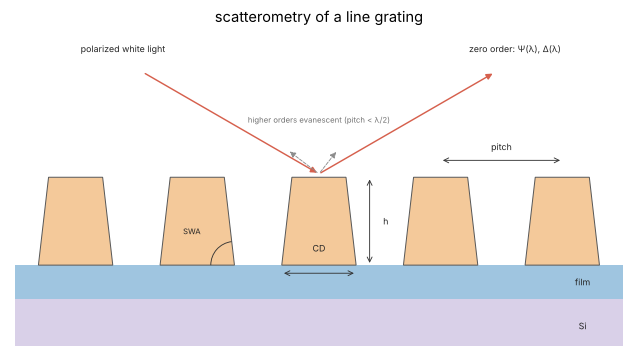

In [2]:
fig, ax = plt.subplots(figsize=(10, 4.4), layout="constrained")
sketch.metrology_layout(ax, "scatterometry", title="scatterometry of a line grating")
plt.show()

## 1. The zero order of a line grating

The test structure: lines of amorphous silicon (a stand-in for the
polysilicon of a gate, Tauc-Lorentz parameters of Jellison and Modine)
with a CD of 40 nm at the bottom, 60 nm high, with a sidewall angle of
87°, at a pitch of 120 nm, on 3 nm of SiO₂ on silicon. Measured at 65°
from 400 to 1000 nm, the first diffraction order would need
$\lambda < p\,(1 + \sin 65°) = 229$ nm: only the zero order propagates.
`sc.grating_layers()` cuts the trapezoid into lamellar slices for the
RCWA, `sc.zero_order_jones()` returns the Jones matrix of the zero order
in the p-s basis, and `sc.psi_delta()` its $\Psi$ and $\Delta$.

one signature (61 wavelengths): 0.49 s


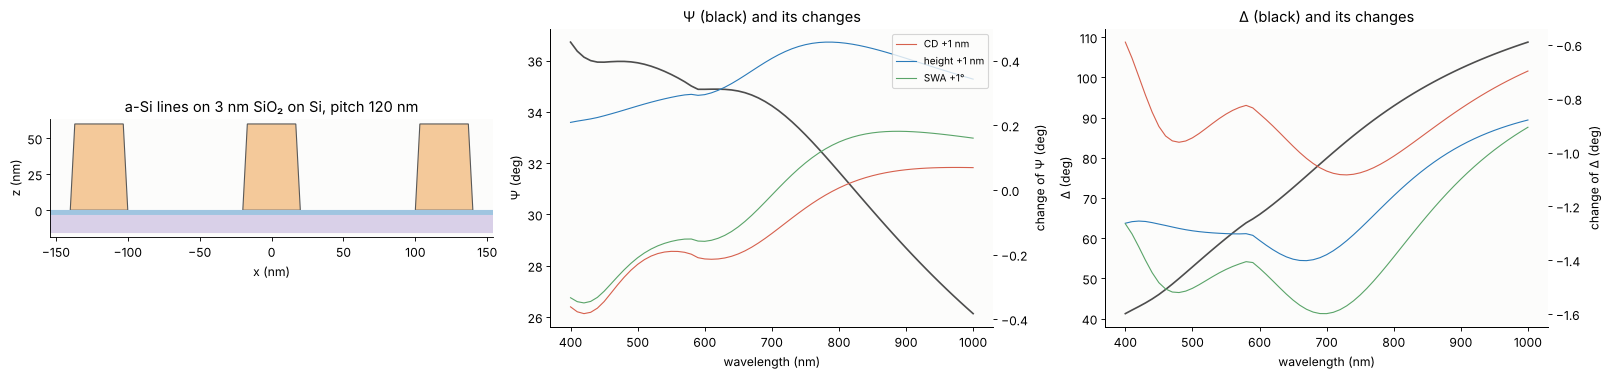

In [3]:
PITCH, ANGLE = 0.120, 65.0
TL_ASI = (122.0, 3.45, 2.54, 1.20, 1.15)


def n_asi(w):
    return el.index_from_eps(el.tauc_lorentz(el.photon_energy(w), *TL_ASI))


def layers_for(cd, height, swa, t_ox=0.003, n_slices=10, top_rounding=0.0, asymmetry=0.0):
    return lambda w: sc.grating_layers(w, PITCH, cd, height, swa, n_asi,
                                       films=[(el.sio2_index, t_ox)], n_slices=n_slices,
                                       top_rounding=top_rounding, asymmetry=asymmetry)


def signature(p, wl, n_orders=8, n_slices=10, azimuth=0.0, **kw):
    """Psi and Delta of the profile p = (cd, height, swa[, t_ox])."""
    J = sc.zero_order_jones(PITCH, layers_for(*p, n_slices=n_slices, **kw), wl, ANGLE,
                            el.silicon_index, azimuth=azimuth, n_orders=n_orders)
    return sc.psi_delta(J)


NOMINAL = (0.040, 0.060, 87.0, 0.003)
wl = np.linspace(0.4, 1.0, 61)
t0 = time.time()
psi0, delta0 = signature(NOMINAL, wl)
print("one signature (61 wavelengths): {:.2f} s".format(time.time() - t0))
fig, axs = plt.subplots(1, 3, figsize=(20, 4.6), layout="constrained")
x, z = sc.profile_outline(0.040, 0.060, 87.0)
for c in (-PITCH, 0, PITCH):
    axs[0].fill(1e3*(x + c), 1e3*z, color="#f4c99a", ec="0.35")
axs[0].axhspan(-3, 0, color="#9fc5e0")
axs[0].axhspan(-15, -3, color="#d9d0e8")
axs[0].set_xlabel("x (nm)")
axs[0].set_ylabel("z (nm)")
axs[0].set_aspect("equal")
axs[0].set_title("a-Si lines on 3 nm SiO₂ on Si, pitch 120 nm")
pert = {"CD +1 nm": ((0.041, 0.060, 87.0, 0.003), RED),
        "height +1 nm": ((0.040, 0.061, 87.0, 0.003), BLUE),
        "SWA +1°": ((0.040, 0.060, 88.0, 0.003), GREEN)}
axs[1].plot(wl*1e3, psi0, color="0.3", lw=1.5, label="nominal")
axs[2].plot(wl*1e3, delta0, color="0.3", lw=1.5)
axs1b, axs2b = axs[1].twinx(), axs[2].twinx()
for name, (p, c) in pert.items():
    ps, ds = signature(p, wl)
    axs1b.plot(wl*1e3, ps - psi0, color=c, lw=1, label=name)
    axs2b.plot(wl*1e3, (ds - delta0 + 180) % 360 - 180, color=c, lw=1)
axs1b.set_ylabel("change of Ψ (deg)")
axs2b.set_ylabel("change of Δ (deg)")
axs[1].set_ylabel("Ψ (deg)")
axs[2].set_ylabel("Δ (deg)")
for ax in axs[1:]:
    ax.set_xlabel("wavelength (nm)")
axs[1].set_title("Ψ (black) and its changes")
axs[2].set_title("Δ (black) and its changes")
axs1b.legend(fontsize=9, loc="upper right")
plt.show()

A nanometre of CD or height changes $\Psi$ and $\Delta$ by tenths of a
degree, ten times the noise of a good ellipsometer; the sidewall angle
acts more weakly. The changes have different spectral shapes, which is
what lets a fit separate the parameters.

Before fitting anything, the forward model must be accurate to well
below these changes: enough Fourier orders and enough slices for the
sloped walls. The convergence below is measured against a reference with
20 orders and 40 slices.

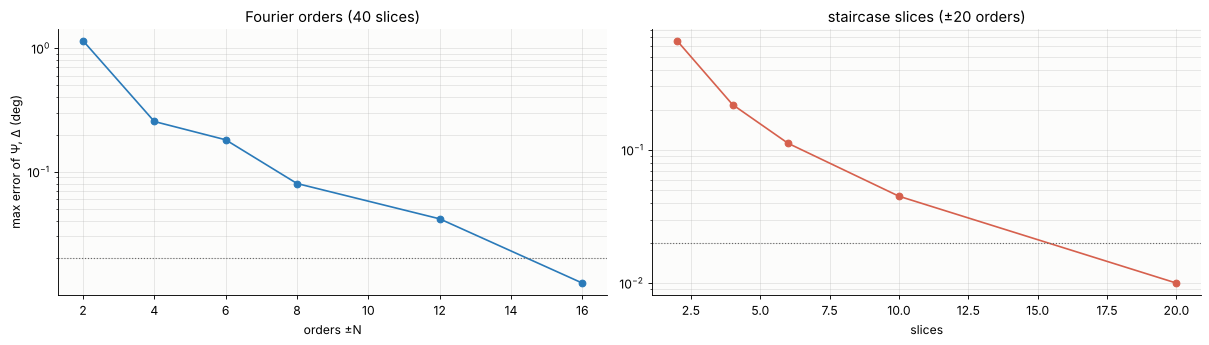

orders +- 2: 1.1519 deg
orders +- 4: 0.2555 deg
orders +- 6: 0.1817 deg
orders +- 8: 0.0805 deg
orders +-12: 0.0417 deg
orders +-16: 0.0126 deg
 2 slices: 0.6617 deg
 4 slices: 0.2192 deg
 6 slices: 0.1123 deg
10 slices: 0.0449 deg
20 slices: 0.0100 deg


In [4]:
wl_c = np.linspace(0.4, 1.0, 13)
ref = signature(NOMINAL, wl_c, n_orders=20, n_slices=40)
orders = (2, 4, 6, 8, 12, 16)
slices = (2, 4, 6, 10, 20)
err_o = [np.max(np.abs(np.concatenate([a - b for a, b in zip(signature(NOMINAL, wl_c, n_orders=o,
                                                                      n_slices=40), ref)])))
         for o in orders]
err_s = [np.max(np.abs(np.concatenate([a - b for a, b in zip(signature(NOMINAL, wl_c, n_orders=20,
                                                                      n_slices=s), ref)])))
         for s in slices]
fig, axs = plt.subplots(1, 2, figsize=(15, 4.2), layout="constrained")
axs[0].semilogy(orders, err_o, "o-", color=BLUE)
axs[0].set_xlabel("orders ±N")
axs[0].set_ylabel("max error of Ψ, Δ (deg)")
axs[0].set_title("Fourier orders (40 slices)")
axs[1].semilogy(slices, err_s, "o-", color=RED)
axs[1].set_xlabel("slices")
axs[1].set_title("staircase slices (±20 orders)")
for ax in axs:
    ax.axhline(0.02, color="0.4", ls=":", lw=1)
    ax.grid(alpha=0.3, which="both")
plt.show()
for o, e in zip(orders, err_o):
    print("orders +-{:2d}: {:.4f} deg".format(o, e))
for s, e in zip(slices, err_s):
    print("{:2d} slices: {:.4f} deg".format(s, e))

The RCWA converges, but not quickly: the lines have an index of about
4.5, and the field in and around them needs many Fourier orders, ±16 to
get below the 0.02° noise of the instrument (dotted). The staircase
converges roughly as one over the number of slices and needs about 20.
The rest of this notebook uses ±8 orders and 10 slices for speed, and
its "measured" data are computed with the same model, so these errors
cancel. In practice they do not: an under-resolved forward model is a
systematic error like any other, and a real scatterometry model is
converged first.

## 2. Sensitivities and correlations

The Jacobian of the signature with respect to the parameters, weighted
with the measurement noise, gives the covariance of the fitted
parameters, $C = (J^T J)^{-1}$. Its diagonal is the precision a fit can
reach, its correlations tell which parameters the data cannot separate.
Four parameters: CD, height, SWA and the thickness of the oxide below
the lines.

CD     : sigma = 0.089 nm
height : sigma = 0.027 nm
SWA    : sigma = 0.079 deg
oxide  : sigma = 0.040 nm


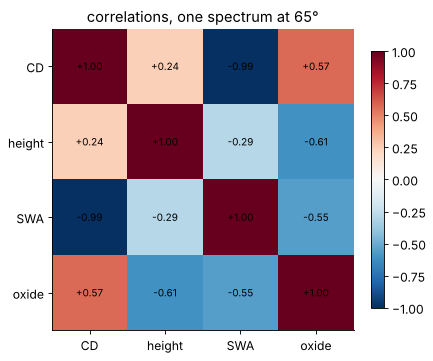

In [5]:
SIG_P, SIG_D = 0.02, 0.04
wl_f = np.linspace(0.4, 1.0, 31)
steps = np.array([0.0005, 0.0005, 0.5, 0.0005])
names = ("CD", "height", "SWA", "oxide")
units = (1e3, 1e3, 1.0, 1e3)
base = signature(NOMINAL, wl_f)
J = []
for i, h in enumerate(steps):
    p = np.array(NOMINAL, dtype=float)
    p[i] += h
    s = signature(p, wl_f)
    J.append(np.concatenate([(s[0] - base[0])/SIG_P, ((s[1] - base[1] + 180) % 360 - 180)/SIG_D])/h)
J = np.array(J).T
cov = np.linalg.inv(J.T @ J)
sd = np.sqrt(np.diag(cov))
corr = cov/np.outer(sd, sd)
for n, s, u in zip(names, sd, units):
    print("{:7s}: sigma = {:.3f} {}".format(n, s*u, "deg" if u == 1.0 else "nm"))
fig, ax = plt.subplots(figsize=(5.5, 4.4), layout="constrained")
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(4), names)
ax.set_yticks(range(4), names)
for i in range(4):
    for j in range(4):
        ax.text(j, i, "{:+.2f}".format(corr[i, j]), ha="center", va="center", fontsize=9)
ax.set_title("correlations, one spectrum at 65°")
plt.colorbar(im, ax=ax, shrink=0.85)
plt.show()

With random noise only, one spectrum determines all four parameters to
a few hundredths of a nanometre and degree, far better than any real
instrument achieves. The strong correlations, CD with SWA and height
with the oxide below, are the real limit: the data constrain
combinations of them (the mean width, the total height), and any
systematic error, of the model or the instrument, is transferred into
the parameters along these directions, amplified. Measuring at more
angles, in a conical mount, or the full Mueller matrix (section 6)
reduces the correlations.

## 3. Library search

The production approach: compute the signatures of a grid of profiles
in advance (a "library"), and for each measurement pick the closest
entry by the noise weighted distance. It is fast and robust against
local minima, and as precise as the grid is fine. Here a coarse library
of 5 × 5 × 4 profiles in CD, height and SWA, with the oxide fixed.

library of 100 signatures: 25 s


true:    CD 41.3 nm, height 58.7 nm, SWA 86.2 deg
library: CD 40.0 nm, height 58.0 nm, SWA 88.0 deg, MSE 70


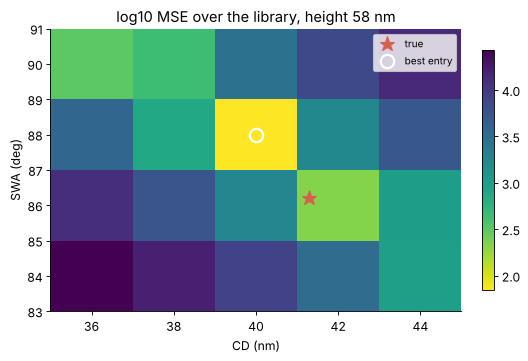

In [6]:
cds = np.arange(0.036, 0.0441, 0.002)
hs = np.arange(0.056, 0.0641, 0.002)
swas = np.arange(84.0, 90.1, 2.0)
t0 = time.time()
library = {}
for cd in cds:
    for h in hs:
        for a in swas:
            library[(cd, h, a)] = signature((cd, h, a, 0.003), wl_f)
print("library of {} signatures: {:.0f} s".format(len(library), time.time() - t0))

rng = np.random.default_rng(5)
TRUE = (0.0413, 0.0587, 86.2, 0.003)
meas = signature(TRUE, wl_f)
meas = (meas[0] + SIG_P*rng.standard_normal(meas[0].shape),
        meas[1] + SIG_D*rng.standard_normal(meas[1].shape))


def chi2(sig, data=meas):
    return np.mean(((sig[0] - data[0])/SIG_P)**2 + (((sig[1] - data[1] + 180) % 360 - 180)/SIG_D)**2)/2


keys = list(library)
cost = np.array([chi2(library[k]) for k in keys])
best = keys[int(np.argmin(cost))]
print("true:    CD {:.1f} nm, height {:.1f} nm, SWA {:.1f} deg".format(TRUE[0]*1e3, TRUE[1]*1e3, TRUE[2]))
print("library: CD {:.1f} nm, height {:.1f} nm, SWA {:.1f} deg, MSE {:.0f}".format(
    best[0]*1e3, best[1]*1e3, best[2], cost.min()))
# the cost over the CD-SWA plane through the best height
C2 = np.array([[chi2(library[(cd, best[1], a)]) for cd in cds] for a in swas])
fig, ax = plt.subplots(figsize=(6.5, 4.4), layout="constrained")
im = ax.pcolormesh(cds*1e3, swas, np.log10(C2), cmap="viridis_r", shading="nearest")
ax.plot(TRUE[0]*1e3, TRUE[2], "*", color=RED, ms=14, label="true")
ax.plot(best[0]*1e3, best[2], "o", mfc="none", mec="white", ms=12, mew=2, label="best entry")
ax.set_xlabel("CD (nm)")
ax.set_ylabel("SWA (deg)")
ax.set_title("log10 MSE over the library, height {:.0f} nm".format(best[1]*1e3))
ax.legend(fontsize=9)
plt.colorbar(im, ax=ax, shrink=0.85)
plt.show()

The library finds the neighbourhood, and the valley of the cost runs
diagonally through the CD-SWA plane: a wider line with steeper walls
looks almost the same as a narrower one with sloped walls, the
correlation of section 2. Its grid of 2 nm and 2° is the resolution.
Production libraries have millions of entries and interpolate between
them; the alternative is regression.

## 4. Regression

Starting from the best library entry, Levenberg-Marquardt adjusts the
four parameters with the RCWA in the loop (`el.fit_psi_delta()` takes
any model of $\Psi$ and $\Delta$).

In [7]:
t0 = time.time()
fit = el.fit_psi_delta(lambda p: signature(p, wl_f), (best[0], best[1], best[2], 0.003),
                       meas[0], meas[1], SIG_P, SIG_D,
                       bounds=([0.02, 0.03, 80.0, 0.0], [0.06, 0.09, 90.0, 0.01]),
                       x_scale=[0.001, 0.001, 1.0, 0.001], diff_step=1e-3)
print("regression: {:.0f} s".format(time.time() - t0))
for n, t, p, s, u in zip(names, TRUE, fit.params, fit.std, units):
    unit = "deg" if u == 1.0 else "nm"
    print("{:7s}: true {:7.2f} {}, fit {:7.2f} +- {:.2f} {}".format(n, t*u, unit, p*u, s*u, unit))
print("MSE {:.2f}".format(fit.mse))

regression: 9 s
CD     : true   41.30 nm, fit   41.14 +- 0.09 nm
height : true   58.70 nm, fit   58.68 +- 0.03 nm
SWA    : true   86.20 deg, fit   86.36 +- 0.08 deg
oxide  : true    3.00 nm, fit    2.96 +- 0.04 nm
MSE 0.91


Regression lands on the true profile within about two standard errors,
which agree with section 2, and the MSE is about 1. It needed a few
dozen RCWA signatures, seconds here and far more for 2D structures
(contact holes, fins) in production, which is why fabs use libraries
or, today, neural network surrogates of the solver for speed, and
regression for accuracy.

## 5. Model errors

Real lines are not trapezoids. Etching rounds the top corners, and the
model must decide what "CD" means for such a profile. Below the
"measured" lines have a top rounding of 15 nm radius; they are fitted
with the trapezoid model and with a model that has the rounding radius
as a fifth parameter.

fits: 31 s
              true  trapezoid model      with rounding
CD           40.00            42.76        40.22 +- 0.31
height       60.00            58.31        59.73 +- 0.18
SWA          87.00            83.80        86.70 +- 0.35
oxide         3.00             3.79         3.02 +- 0.09
rounding     15.00              nan        13.72 +- 0.88
MSE: trapezoid 2.4, with rounding 0.68


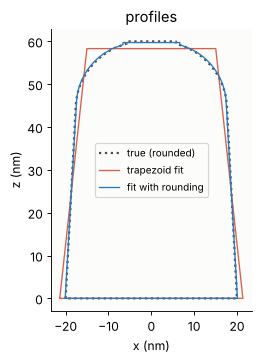

In [8]:
TRUE_R = (0.040, 0.060, 87.0, 0.003)
R_TOP = 0.015
meas_r = signature(TRUE_R, wl_f, top_rounding=R_TOP)
meas_r = (meas_r[0] + SIG_P*rng.standard_normal(meas_r[0].shape),
          meas_r[1] + SIG_D*rng.standard_normal(meas_r[1].shape))
t0 = time.time()
fit_t = el.fit_psi_delta(lambda p: signature(p, wl_f), NOMINAL, meas_r[0], meas_r[1], SIG_P, SIG_D,
                         bounds=([0.02, 0.03, 75.0, 0.0], [0.06, 0.09, 90.0, 0.01]),
                         x_scale=[0.001, 0.001, 1.0, 0.001], diff_step=1e-3)
fit_rr = el.fit_psi_delta(lambda p: signature(p[:4], wl_f, top_rounding=p[4]), list(NOMINAL) + [0.008],
                          meas_r[0], meas_r[1], SIG_P, SIG_D,
                          bounds=([0.02, 0.03, 75.0, 0.0, 0.0], [0.06, 0.09, 90.0, 0.01, 0.03]),
                          x_scale=[0.001, 0.001, 1.0, 0.001, 0.001], diff_step=1e-3)
print("fits: {:.0f} s".format(time.time() - t0))
print("{:9s} {:>8s} {:>16s} {:>18s}".format("", "true", "trapezoid model", "with rounding"))
for i, (n, u) in enumerate(zip(names + ("rounding",), units + (1e3,))):
    t = (list(TRUE_R) + [R_TOP])[i]
    a = fit_t.params[i]*u if i < 4 else float("nan")
    print("{:9s} {:8.2f} {:16.2f} {:12.2f} +- {:.2f}".format(n, t*u, a, fit_rr.params[i]*u, fit_rr.std[i]*u))
print("MSE: trapezoid {:.1f}, with rounding {:.2f}".format(fit_t.mse, fit_rr.mse))
fig, ax = plt.subplots(figsize=(7, 4.4), layout="constrained")
for (p, r), c, lab in (((TRUE_R, R_TOP), "0.3", "true (rounded)"),
                       ((fit_t.params, 0.0), RED, "trapezoid fit"),
                       ((fit_rr.params, fit_rr.params[4]), BLUE, "fit with rounding")):
    x, z = sc.profile_outline(p[0], p[1], p[2], top_rounding=r, n_slices=60)
    ax.plot(x*1e3, z*1e3, color=c, lw=2 if c == "0.3" else 1.2, ls="-" if c != "0.3" else ":",
            label=lab)
ax.set_aspect("equal")
ax.set_xlabel("x (nm)")
ax.set_ylabel("z (nm)")
ax.legend(fontsize=9)
ax.set_title("profiles")
plt.show()

The trapezoid cannot describe the rounded top and compensates for it:
a wider bottom with flatter walls, a lower line and a thicker oxide,
errors of several nanometres and degrees, far outside the statistical
uncertainties of section 2. The MSE rises only to about 2, a warning
that is easily overlooked. With the rounding in the model, parameters
and MSE are right again. Which model is right is decided by the MSE, by
comparison with cross sections from electron microscopy (TEM) and by
consistency over many wafers, never by the fit alone. This is why
scatterometry models are built with care for each process step, and why
this module has no library or calibration machinery: those belong to
the model of a specific process.

## 6. Asymmetric lines and the Mueller matrix

Etch tools can tilt the profile: one sidewall steeper than the other.
In the planar mount (plane of incidence across the lines) a profile and
its mirror image give the same zero order, so $\Psi$ and $\Delta$ cannot
tell the sign of an asymmetry and depend on it only to second order. In
a **conical mount** the plane of incidence is rotated against the
grating vector; the lines then couple p and s, the reflection is
described by a full Mueller matrix (`sc.mueller_from_jones()`), and for
a symmetric profile at the azimuth of 90° the off-diagonal blocks
vanish by symmetry (Novikova et al. 2006). An asymmetry breaks it: the
off-diagonal elements grow linearly with the asymmetry and change sign
with it, a direct measurement of the tilt that Mueller matrix
ellipsometers in fabs use, also for overlay.

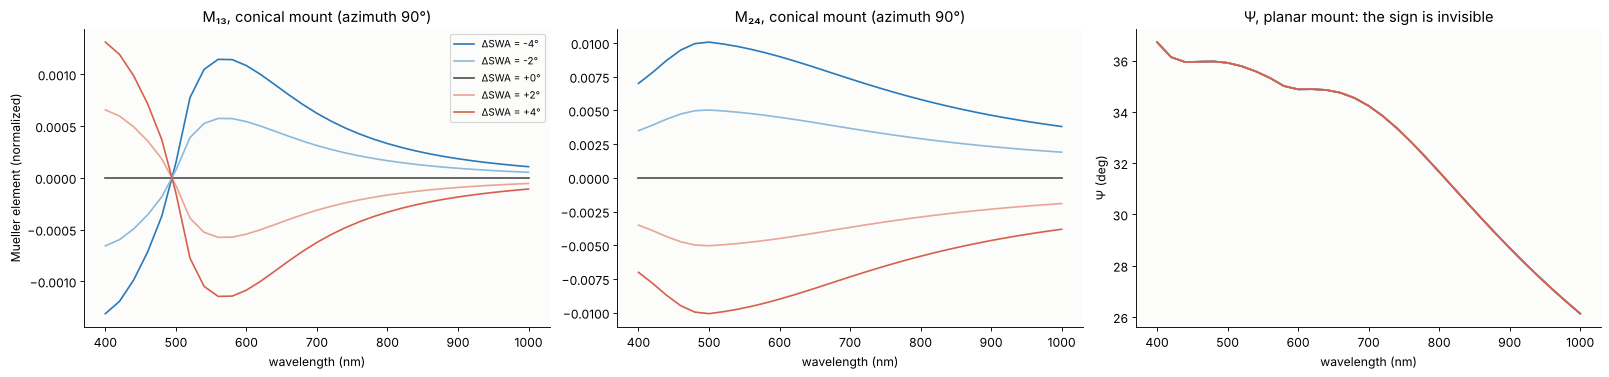

M24 at 500 nm against the asymmetry: -4 deg: +0.0101, -2 deg: +0.0050, +0 deg: +0.0000, +2 deg: -0.0050, +4 deg: -0.0101


In [9]:
wl_m = np.linspace(0.4, 1.0, 31)
asyms = (-4.0, -2.0, 0.0, 2.0, 4.0)
cols = (BLUE, "#8fb9d9", "0.3", "#e9a597", RED)
fig, axs = plt.subplots(1, 3, figsize=(20, 4.6), layout="constrained")
M13_550 = []
for a, c in zip(asyms, cols):
    J = sc.zero_order_jones(PITCH, layers_for(0.040, 0.060, 87.0, asymmetry=a), wl_m, ANGLE,
                            el.silicon_index, azimuth=90.0, n_orders=8)
    M = sc.mueller_from_jones(J)
    axs[0].plot(wl_m*1e3, M[:, 0, 2], color=c, label="ΔSWA = {:+.0f}°".format(a))
    axs[1].plot(wl_m*1e3, M[:, 1, 3], color=c)
    J0 = sc.zero_order_jones(PITCH, layers_for(0.040, 0.060, 87.0, asymmetry=a), wl_m, ANGLE,
                             el.silicon_index, azimuth=0.0, n_orders=8)
    axs[2].plot(wl_m*1e3, sc.psi_delta(J0)[0], color=c)
    M13_550.append(M[np.argmin(np.abs(wl_m - 0.50)), 1, 3])
axs[0].set_title("M₁₃, conical mount (azimuth 90°)")
axs[1].set_title("M₂₄, conical mount (azimuth 90°)")
axs[2].set_title("Ψ, planar mount: the sign is invisible")
axs[0].set_ylabel("Mueller element (normalized)")
axs[2].set_ylabel("Ψ (deg)")
for ax in axs:
    ax.set_xlabel("wavelength (nm)")
axs[0].legend(fontsize=9)
plt.show()
print("M24 at 500 nm against the asymmetry:", ", ".join("{:+.0f} deg: {:+.4f}".format(a, m)
                                                    for a, m in zip(asyms, M13_550)))

The off-diagonal elements are zero for the symmetric line and follow
the asymmetry with its sign: $M_{24}$ by about 0.0025 per degree of
sidewall asymmetry, $M_{13}$ by a tenth of that, against a noise of
about 0.001 of a good Mueller ellipsometer. In the planar mount the
curves for +4° and −4° lie on top of each other.

## Summary

- Gratings with pitches below the wavelength reflect only the zero order;
  its $\Psi$ and $\Delta$ depend on the line profile with a sensitivity of
  tenths of a degree per nanometre.
- The rigorous forward model (RCWA with enough orders and slices) must be
  accurate to well below the measurement noise.
- The parameters are found by library search or regression; the
  statistical precision is excellent, but strong correlations (CD with
  SWA, height with the films below) transfer systematic errors into the
  result.
- A profile the model cannot describe gives biased parameters and a high
  MSE; the model is the measurement.
- Asymmetric profiles are invisible in the planar mount but appear in
  the off-diagonal Mueller elements of a conical mount.

## References

- C. J. Raymond, M. R. Murnane, S. S. H. Naqvi and J. R. McNeil,
  "Metrology of subwavelength photoresist gratings using optical
  scatterometry", J. Vac. Sci. Technol. B 13, 1484 (1995).
- X. Niu, N. Jakatdar, J. Bao and C. J. Spanos, "Specular spectroscopic
  scatterometry", IEEE Trans. Semicond. Manuf. 14, 97 (2001).
- H.-T. Huang, W. Kong and F. L. Terry, "Normal-incidence spectroscopic
  ellipsometry for critical dimension monitoring", Appl. Phys. Lett. 78,
  3983 (2001).
- T. Novikova, A. De Martino, S. Ben Hatit and B. Drévillon, "Application
  of Mueller polarimetry in conical diffraction for critical dimension
  measurements in microelectronics", Appl. Opt. 45, 3688 (2006).
- L. Li, "Use of Fourier series in the analysis of discontinuous
  periodic structures", J. Opt. Soc. Am. A 13, 1870 (1996).
- N. G. Orji, M. Badaroglu, B. M. Barnes et al., "Metrology for the next
  generation of semiconductor devices", Nat. Electron. 1, 532 (2018).

In [10]:
print("run time: {:.0f} s".format(time.time() - t_start))

run time: 81 s
